# Aperture Mass Statistics Tutorial

`make_map3` computes the third-order aperture mass statistic

$$\langle M_\mathrm{ap}^3 \rangle(\theta_1, \theta_2, \theta_3) =
    \frac{2}{8\pi^3} \int_0^\infty d\ell_1 \int_0^\infty d\ell_2
    \int_0^\pi d\varphi\; \ell_1 \ell_2\,
    B_\kappa(\ell_1, \ell_2, \ell_3)\,
    \hat u(\ell_1\theta_1)\, \hat u(\ell_2\theta_2)\, \hat u(\ell_3\theta_3)$$

from the Limber-projected convergence bispectrum $B_\kappa$ (see `projected_bihalofit_tutorial.ipynb`),
where $\ell_3 = \sqrt{\ell_1^2+\ell_2^2+2\ell_1\ell_2\cos\varphi}$ closes the Fourier triangle and
$\hat u(\eta) = \tfrac12\eta^2 e^{-\eta^2/2}$ is the Crittenden (2002) aperture filter. The pattern is the
same as for the other bispectra:

```python
map3 = make_map3(dndz, tracers, N_ell=..., N_phi=...)   # once: quadrature grid, n(z), tracers
M3   = map3(theta1, theta2, theta3, cosmo)              # then: any apertures, any Cosmology
```

`M3` has shape `(N_cosmo, N_theta)`. Angles are in **radians** throughout, and `ARCMIN_TO_RAD` converts
from arcmin. The whole pipeline is pure JAX, so it can be differentiated with respect to every
cosmological parameter. Source: `src/aperture.py`.

## 0. Setup

Imports `bihalofit_jax`, which must be installed.

In [1]:
import sys, os

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'
os.environ['TF_FORCE_GPU_ALLOW_GROWTH'] = 'true'

import bihalofit_jax    # pip install bihalofit-jax, or pip install -e . from a checkout

import numpy as np
import jax
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from bihalofit_jax import Cosmology, make_map3, smail_nz, ARCMIN_TO_RAD

# Figure style: boxed axes with inward ticks on all four sides, no grid, no titles, 2-point lines,
# a colour-blind-safe cycle, one fixed colour per backend, and a single-hue blue ramp for ordered quantities.
plt.rcParams.update({
    'figure.figsize': (7.5, 4.8), 'figure.dpi': 110, 'figure.constrained_layout.use': True,
    'font.family': 'serif', 'mathtext.fontset': 'cm', 'font.size': 14, 'axes.labelsize': 16,
    'axes.linewidth': 0.8, 'axes.grid': False, 'xtick.labelsize': 13, 'ytick.labelsize': 13,
    'xtick.major.size': 5, 'ytick.major.size': 5, 'xtick.minor.size': 2.5, 'ytick.minor.size': 2.5,
    'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True,
    'xtick.minor.visible': True, 'ytick.minor.visible': True,
    'lines.linewidth': 2, 'lines.solid_capstyle': 'round', 'legend.frameon': False, 'legend.fontsize': 13,
    'axes.prop_cycle': plt.cycler(color=['#2a78d6', '#eb6834', '#1baf7a', '#eda100']),
})
BLUES  = LinearSegmentedColormap.from_list('blues', ['#86b6ef', '#184f95'])
COLOUR = {'baccoemu': '#2a78d6', 'syren': '#eb6834', 'eh': '#1baf7a', 'eh_99': '#eda100'}
print('bihalofit_jax:', bihalofit_jax.__file__)
print('JAX device:', jax.devices())

bihalofit_jax: /tmp/bihalofit_jax_tutorials/lib/python3.12/site-packages/bihalofit_jax/__init__.py
JAX device: [CpuDevice(id=0)]


## 1. Source redshift distribution

Also used by `make_projected_bihalofit`. A distribution is passed as a `(z, n(z))` tuple.

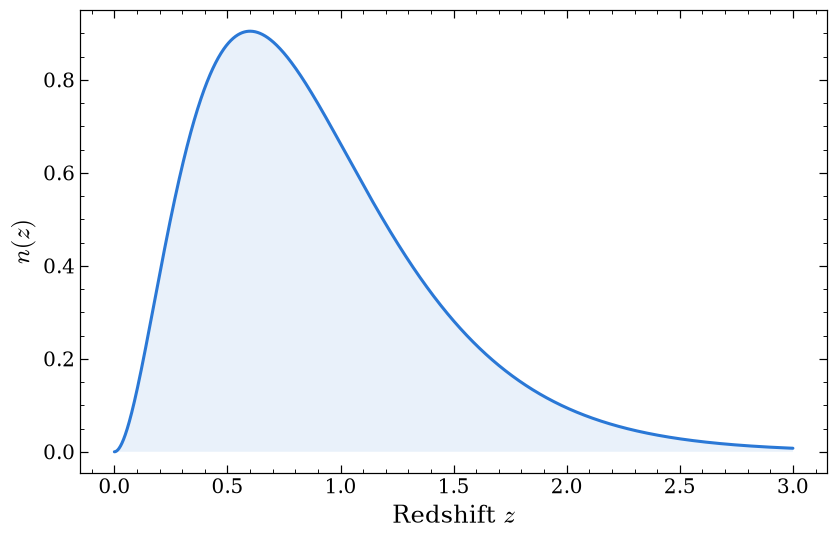

In [2]:
z_arr  = np.linspace(0.0, 3.0, 2000)
nz_arr = smail_nz(z_arr, z0=0.3, alpha=2.0, beta=1.0)      # LSST-like Smail distribution
n_z    = (z_arr, nz_arr)

fig, ax = plt.subplots()
ax.plot(z_arr, nz_arr)
ax.fill_between(z_arr, nz_arr, alpha=0.1)
ax.set_xlabel('Redshift $z$'); ax.set_ylabel(r'$n(z)$')
plt.show()

## 2. Build once, evaluate on any apertures

`make_map3` is a builder: it constructs the $(\ell_1,\ell_2,\varphi)$ quadrature grid, compiles
`make_projected_bihalofit` on it, and returns a fast callable. Cosmological parameters and aperture radii go
to the callable, not to the builder. `dndz` holds one $n(z)$ per leg and `tracers` one kernel per leg:
`'lensing'` on all three is classic cosmic shear (section 6 mixes them).

- **Resolution.** `N_ell` and `N_phi` (with `N_rho=48`) set the resolution of the default `'diagonal'`
  grid, of size `N_ell * N_rho * N_phi`. They are set below the defaults (96 and 64) for speed: 32 is within
  about 0.5% of 48 over $1'$–$60'$, but 16 is 12% off.
- **`theta_min`** sets the upper limit of the $\ell$ integral, $\ell_{\max}=10/\theta_{\min}$, because the
  Crittenden filter needs $\ell$ up to that. Without it a fixed $2\times10^4$ is used, which can truncate
  the signal for apertures below about $1.7'$.
- **The `RuntimeWarning` below is expected.** The apertures probe $k=\ell/\chi$ up to several thousand $h$/Mpc, beyond the
  default $P_{\rm L}$ grid (50 $h$/Mpc), so the build warns that it is extrapolated. For cosmic shear this changes
  $\langle M_{\rm ap}^3\rangle$ by less than 0.01%; pass `k_lin` (up to `1e4`) to remove the warning.


/tmp/bihalofit_jax_tutorials/lib/python3.12/site-packages/bihalofit_jax/aperture.py:336: RuntimeWarning: k = (ell + 0.5)/chi out of P_L grid [1.00e-04, 5.00e+01] h/Mpc for 3.1% of the Limber weight (k up to 6.61e+03); P_L is extrapolated there as a power law. Above k_NL BiHalofit uses P_L only in its suppressed 3-halo term, so the effect is usually small; pass a wider k_lin to remove it.
  projected_bihalofit = make_projected_bihalofit(


(1, 25)


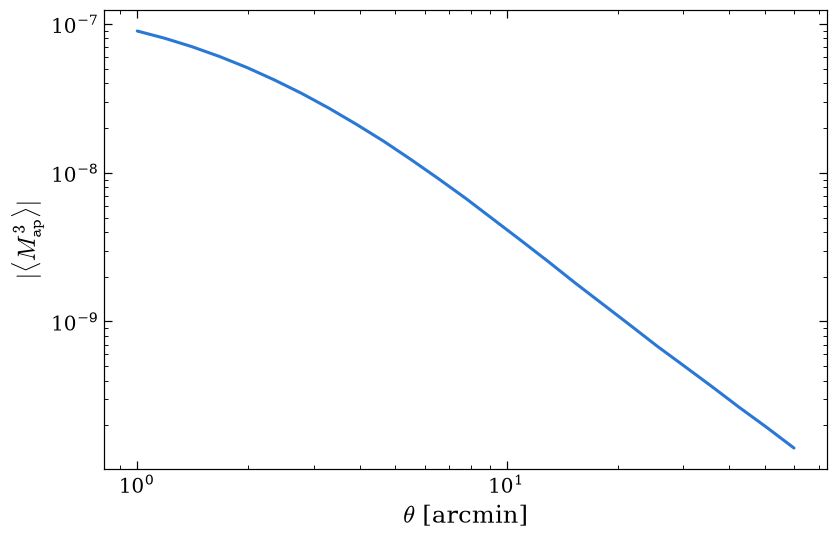

In [3]:
cosmo = Cosmology(omega_cold=np.array([0.3089]), omega_baryon=np.array([0.0486]),
                  sigma8_cold=np.array([0.8159]), ns=np.array([0.9667]), hubble=np.array([0.6774]))
# neutrino_mass, w0 and wa keep their defaults (0, -1, 0)

theta_arcmin = np.geomspace(1.0, 60.0, 25)
theta        = theta_arcmin * ARCMIN_TO_RAD                # equilateral apertures, in radians

map3 = make_map3((n_z, n_z, n_z), ('lensing',) * 3, N_ell=32, N_phi=32, theta_min=theta[0], pk_source='syren')
M3   = map3(theta, theta, theta, cosmo)                    # (N_cosmo, N_theta) = (1, 25)
print(M3.shape)

fig, ax = plt.subplots()
ax.loglog(theta_arcmin, np.abs(M3[0]))
ax.set_xlabel(r'$\theta$ [arcmin]'); ax.set_ylabel(r'$|\langle M_\mathrm{ap}^3\rangle|$')
plt.show()

## 3. Linear $P(k)$ backends

`pk_source` selects the linear power spectrum: `'syren'` (default, an analytic fit), `'baccoemu'` (a
neural-network emulator that needs TensorFlow), `'eh'` (Eisenstein & Hu 1998, no wiggles) and `'eh_99'` (Eisenstein
& Hu 1999 at $f_\nu=0$, added to cross-validate against `threepoint_py`); all but `'baccoemu'` are pure JAX.

Loading sigma8 emulator...
Sigma8 emulator loaded in memory.
Loading linear emulator...
Linear emulator loaded in memory.
Loading no-wiggles emulator...
No-wiggles emulator loaded in memory.
Loading non-linear emulator...
Nonlinear emulator loaded in memory.
Loading Baryonic Emulator Arico et al. (2021)...
Baryonic Emulator Arico et al. (2025) loaded in memory.


/tmp/bihalofit_jax_tutorials/lib/python3.12/site-packages/bihalofit_jax/aperture.py:336: RuntimeWarning: chi_max=5800 Mpc/h reaches a(chi) ~ 0.084 for high-Omega_m cosmologies, below the baccoemu emulator's trained expfactor bound 0.1; the emulator would extrapolate silently on the deepest chi-nodes. Reduce chi_max or use pk_source='syren'/'eh'.
  projected_bihalofit = make_projected_bihalofit(
/tmp/bihalofit_jax_tutorials/lib/python3.12/site-packages/bihalofit_jax/aperture.py:336: RuntimeWarning: k = (ell + 0.5)/chi out of P_L grid [1.00e-04, 5.00e+01] h/Mpc for 3.1% of the Limber weight (k up to 6.61e+03); P_L is extrapolated there as a power law. Above k_NL BiHalofit uses P_L only in its suppressed 3-halo term, so the effect is usually small; pass a wider k_lin to remove it.
  projected_bihalofit = make_projected_bihalofit(


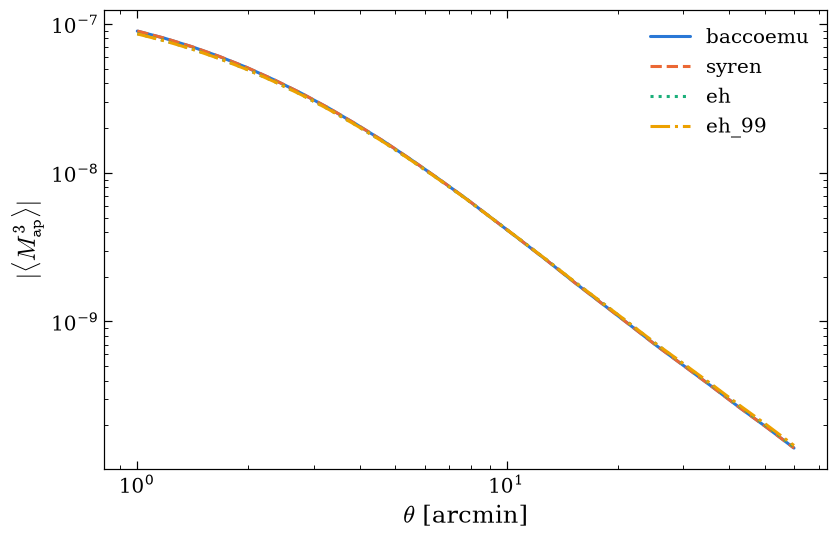

In [4]:
backends = ['baccoemu', 'syren', 'eh', 'eh_99']
M3_backends = {b: make_map3((n_z, n_z, n_z), ('lensing',) * 3, N_ell=32, N_phi=32, theta_min=theta[0],
                            pk_source=b)(theta, theta, theta, cosmo) for b in backends}

fig, ax = plt.subplots()
for b, ls in zip(backends, ('-', '--', ':', '-.')):
    ax.loglog(theta_arcmin, np.abs(M3_backends[b][0]), ls=ls, color=COLOUR[b], label=b)
ax.set_xlabel(r'$\theta$ [arcmin]'); ax.set_ylabel(r'$|\langle M_\mathrm{ap}^3\rangle|$'); ax.legend()
plt.show()

## 4. Multiple cosmologies

Give the `Cosmology` fields arrays of length `N_cosmo`; `map3` evaluates all of them in one call and the
output is `(N_cosmo, N_theta)`. Here, 20 values of $\sigma_8$.

(20, 25)


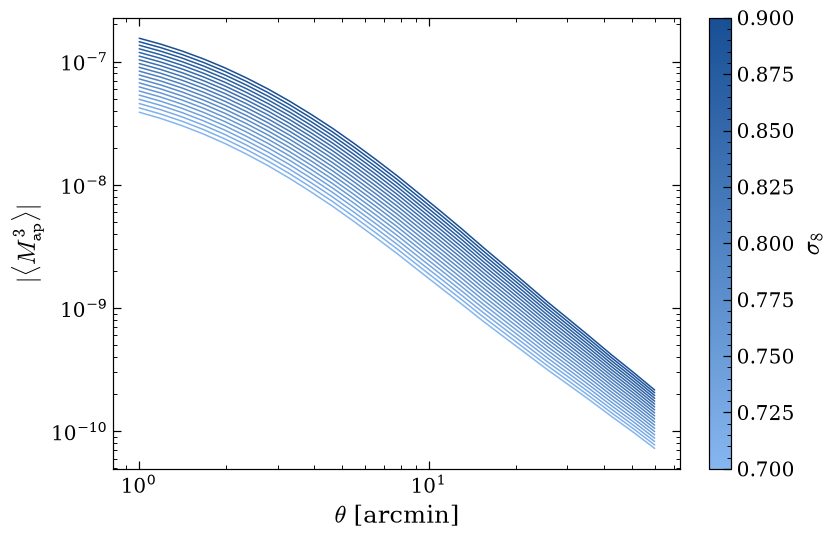

In [5]:
N = 20
sigma8 = np.linspace(0.7, 0.9, N)
ones   = np.ones(N)
cosmos = Cosmology(omega_cold=0.3089 * ones, omega_baryon=0.0486 * ones, sigma8_cold=sigma8,
                   ns=0.9667 * ones, hubble=0.6774 * ones)

M3_multi = np.asarray(map3(theta, theta, theta, cosmos))   # (N_cosmo, N_theta) = (20, 25)
print(M3_multi.shape)

fig, ax = plt.subplots()
for i in range(N):
    ax.loglog(theta_arcmin, np.abs(M3_multi[i]), color=BLUES(i / (N - 1)), lw=1)
plt.colorbar(plt.cm.ScalarMappable(cmap=BLUES, norm=plt.Normalize(0.7, 0.9)), ax=ax, label=r'$\sigma_8$')
ax.set_xlabel(r'$\theta$ [arcmin]'); ax.set_ylabel(r'$|\langle M_\mathrm{ap}^3\rangle|$')
plt.show()

## 5. Derivatives with JAX

`map3` is a pure JAX function, so JAX's transformations apply to it directly. It takes the apertures before
the cosmology, so `argnums=3` tells `jax.jacfwd` to differentiate with respect to the fourth argument, the
`Cosmology`. Because `Cosmology` is a pytree, the result is another `Cosmology` whose fields hold the
derivatives: `jac.omega_cold` is $\partial\langle M_\mathrm{ap}^3\rangle/\partial\Omega_{\rm cold}$. Each has
shape `(N_cosmo, N_theta, N_cosmo)`: the axes of `M3`, then the shape of the parameter.

Below are the responses $d\ln\langle M_\mathrm{ap}^3\rangle/d\ln\theta_{\rm par}$ to $\Omega_{\rm cold}$ and
$\sigma_8$: the percentage change for a 1% change in the parameter, with the others held fixed.

(1, 25, 1)


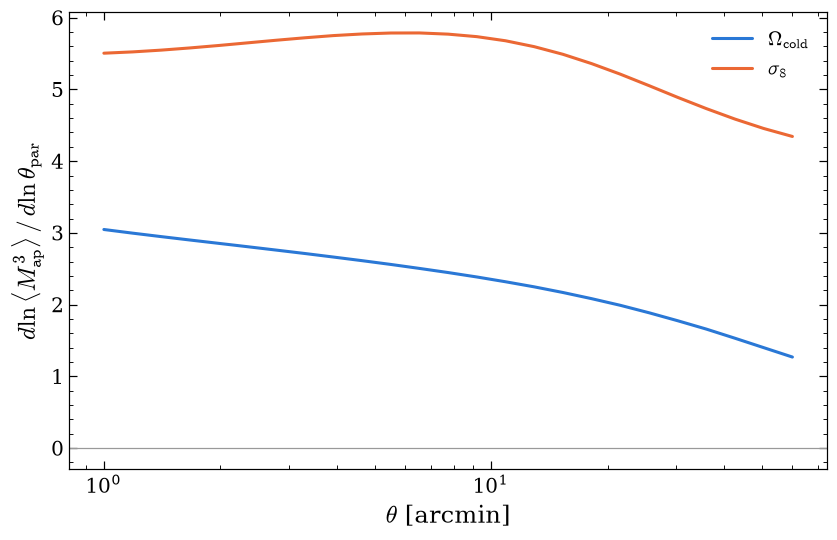

In [6]:
jac = jax.jacfwd(map3, argnums=3)(theta, theta, theta, cosmo)      # a Cosmology whose fields are derivatives
print(jac.omega_cold.shape)                                        # (N_cosmo, N_theta, N_cosmo) = (1, 25, 1)

dlnM_dlnOmega  = jac.omega_cold[0, :, 0] / M3[0] * cosmo.omega_cold[0]
dlnM_dlnsigma8 = jac.sigma8_cold[0, :, 0] / M3[0] * cosmo.sigma8_cold[0]

fig, ax = plt.subplots()
ax.semilogx(theta_arcmin, dlnM_dlnOmega, label=r'$\Omega_{\rm cold}$')
ax.semilogx(theta_arcmin, dlnM_dlnsigma8, label=r'$\sigma_8$')
ax.axhline(0, color='0.6', lw=0.8)
ax.set_xlabel(r'$\theta$ [arcmin]'); ax.set_ylabel(r'$d\ln\langle M_\mathrm{ap}^3\rangle\,/\,d\ln\theta_{\rm par}$'); ax.legend()
plt.show()

## 6. Mixing tracers: $\langle N_\mathrm{ap} M_\mathrm{ap}^2\rangle$

`'lensing'` on all three legs is the classic cosmic-shear $\langle M_\mathrm{ap}^3\rangle$. As for
`make_projected_bihalofit`, each leg can take its own tracer, so `'counts'` on one leg and `'lensing'` on
the other two gives $\langle N_\mathrm{ap} M_\mathrm{ap}^2\rangle$ (galaxy-galaxy-lensing-like). The same
Crittenden filter is applied to every leg whatever its tracer (see the module docstring for the assumption).

/tmp/bihalofit_jax_tutorials/lib/python3.12/site-packages/bihalofit_jax/aperture.py:336: RuntimeWarning: k = (ell + 0.5)/chi out of P_L grid [1.00e-04, 5.00e+01] h/Mpc for 1.5% of the Limber weight (k up to 6.61e+03); P_L is extrapolated there as a power law. Above k_NL BiHalofit uses P_L only in its suppressed 3-halo term, so the effect is usually small; pass a wider k_lin to remove it.
  projected_bihalofit = make_projected_bihalofit(


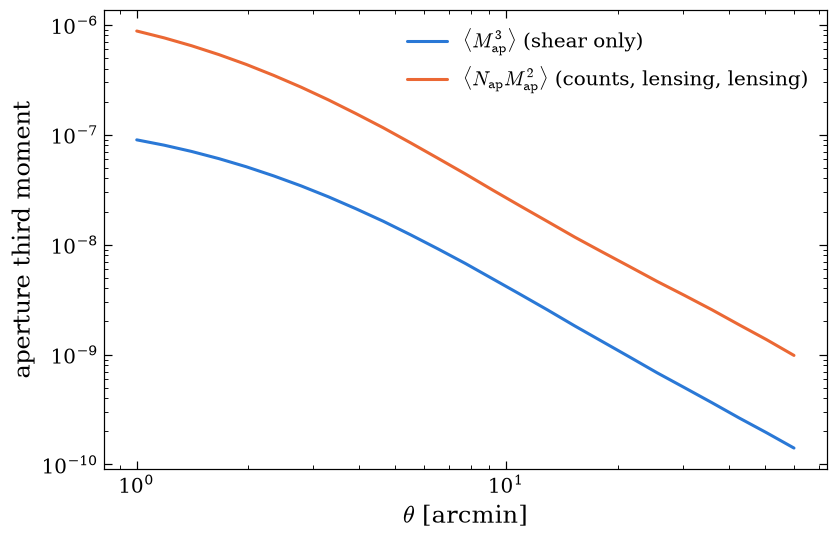

In [7]:
z_lens   = np.linspace(0.0, 3.0, 2000)
lens_n_z = (z_lens, smail_nz(z_lens, z0=0.4, alpha=2.0, beta=1.0))      # a lower-redshift lens sample

map3_nap = make_map3((lens_n_z, n_z, n_z), ('counts', 'lensing', 'lensing'), bias=(1.7, None, None),
                     N_ell=32, N_phi=32, theta_min=theta[0], pk_source='syren')

fig, ax = plt.subplots()
ax.loglog(theta_arcmin, np.abs(M3[0]), label=r'$\langle M_\mathrm{ap}^3\rangle$ (shear only)')
ax.loglog(theta_arcmin, np.abs(map3_nap(theta, theta, theta, cosmo)[0]),
          label=r'$\langle N_\mathrm{ap} M_\mathrm{ap}^2\rangle$ (counts, lensing, lensing)')
ax.set_xlabel(r'$\theta$ [arcmin]'); ax.set_ylabel('aperture third moment'); ax.legend()
plt.show()